In [2]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

from src.logreg import (
    fitScaling,
    applyScaling,
    fitLogreg,
    predictLogreg
)

loading datset

In [3]:
Shots = pd.read_parquet("../data/features/shots_features.parquet")

print("Total shots:", len(Shots))
print("Total columns:", len(Shots.columns))

print("\nTrain/test split:")
print(Shots["test"].value_counts())

print("\nValidation folds:")
print(Shots.groupby(["test", "fold"]).size())

Total shots: 99746
Total columns: 42

Train/test split:
test
False    74944
True     24802
Name: count, dtype: int64

Validation folds:
test   fold
False  1       15047
       2       14992
       3       15056
       4       14943
       5       14906
True   0       24802
dtype: int64


selectuibg our training and valodatinf data

In [4]:
TrainShots = Shots[
    (Shots["test"] == False) & (Shots["fold"] != 1)
].copy()

ValidShots = Shots[
    (Shots["test"] == False) & (Shots["fold"] == 1)
].copy()

print("Training shots:", len(TrainShots))
print("Validation shots:", len(ValidShots))

print("Training goal rate:", round(TrainShots["goal"].mean() * 100, 2), "%")
print("Validation goal rate:", round(ValidShots["goal"].mean() * 100, 2), "%")

print(
    "Matches shared between training and validation:",
    len(set(TrainShots["match_id"]) & set(ValidShots["match_id"]))
)

Training shots: 59897
Validation shots: 15047
Training goal rate: 10.15 %
Validation goal rate: 10.59 %
Matches shared between training and validation: 0


In [5]:
FeatureNames = ["distance", "angle"]

XTrain = TrainShots[FeatureNames].to_numpy(dtype=float)
YTrain = TrainShots["goal"].to_numpy(dtype=int)

XValid = ValidShots[FeatureNames].to_numpy(dtype=float)
YValid = ValidShots["goal"].to_numpy(dtype=int)

print("Training features:", XTrain.shape)
print("Validation features:", XValid.shape)

print("Missing training values:", np.isnan(XTrain).sum())
print("Missing validation values:", np.isnan(XValid).sum())

Training features: (59897, 2)
Validation features: (15047, 2)
Missing training values: 0
Missing validation values: 0


In [6]:
Mean, Std = fitScaling(XTrain)

XTrainScaled = applyScaling(XTrain, Mean, Std)
XValidScaled = applyScaling(XValid, Mean, Std)

print("Training mean:", np.mean(XTrainScaled, axis=0))
print("Training std:", np.std(XTrainScaled, axis=0))

print("Validation shape:", XValidScaled.shape)

print("Missing training values:", np.isnan(XTrainScaled).sum())
print("Missing validation values:", np.isnan(XValidScaled).sum())

Training mean: [-1.59435270e-16  3.32156813e-17]
Training std: [1. 1.]
Validation shape: (15047, 2)
Missing training values: 0
Missing validation values: 0


trainng our leg reg model 

In [7]:
Weights, Bias = fitLogreg(
    XTrainScaled,
    YTrain,
    LearningRate=0.1,
    Iterations=2000
)

TrainProbabilities = predictLogreg(XTrainScaled, Weights, Bias)
ValidProbabilities = predictLogreg(XValidScaled, Weights, Bias)

TrainAUC = roc_auc_score(YTrain, TrainProbabilities)
ValidAUC = roc_auc_score(YValid, ValidProbabilities)

print("Weights:", Weights)
print("Bias:", Bias)
print("Training AUC:", round(TrainAUC, 4))
print("Validation AUC:", round(ValidAUC, 4))

Weights: [-0.59676918  0.34491091]
Bias: -2.4808796156316766
Training AUC: 0.7409
Validation AUC: 0.7436


comparing againsr scikit learn 

In [9]:
SklearnModel = LogisticRegression(
    max_iter=2000,
    C=1000000
)

SklearnModel.fit(XTrainScaled, YTrain)

SklearnProbabilities = SklearnModel.predict_proba(XValidScaled)[:, 1]

SklearnAUC = roc_auc_score(YValid, SklearnProbabilities)

print("NumPy validation AUC:", round(ValidAUC, 4))
print("Sklearn validation AUC:", round(SklearnAUC, 4))
print("AUC difference:", round(abs(ValidAUC - SklearnAUC), 6))
print("Within 0.005:", abs(ValidAUC - SklearnAUC) <= 0.005)

NumPy validation AUC: 0.7436
Sklearn validation AUC: 0.7436
AUC difference: 2.6e-05
Within 0.005: True


In [10]:
print("NumPy weights:", Weights)
print("Sklearn weights:", SklearnModel.coef_[0])

print("NumPy bias:", Bias)
print("Sklearn bias:", SklearnModel.intercept_[0])

print(
    "Maximum weight difference:",
    np.max(np.abs(Weights - SklearnModel.coef_[0]))
)

NumPy weights: [-0.59676918  0.34491091]
Sklearn weights: [-0.61378578  0.33566344]
NumPy bias: -2.4808796156316766
Sklearn bias: -2.486249973196486
Maximum weight difference: 0.017016594051172174


preping full feat log reg

In [11]:
ExcludeColumns = ["id", "match_id", "test", "fold", "goal", "x", "y"]

AllFeatures = [
    Column for Column in Shots.columns
    if Column not in ExcludeColumns
]

print("Total modeling features:", len(AllFeatures))
print("\nFeatures:")
print(AllFeatures)

print("\nMissing training values:")
print(TrainShots[AllFeatures].isna().sum().loc[lambda Values: Values > 0])

Total modeling features: 35

Features:
['distance', 'angle', 'visible', 'defendersInCone', 'teammatesInCone', 'nearestDefender', 'defendersWithin3', 'keeperMissing', 'keeperInCone', 'keeperToGoal', 'keeperToShooter', 'shot_body_part_Head', 'shot_body_part_Left Foot', 'shot_body_part_Other', 'shot_body_part_Right Foot', 'shot_technique_Backheel', 'shot_technique_Diving Header', 'shot_technique_Half Volley', 'shot_technique_Lob', 'shot_technique_Normal', 'shot_technique_Overhead Kick', 'shot_technique_Volley', 'shot_type_Corner', 'shot_type_Free Kick', 'shot_type_Kick Off', 'shot_type_Open Play', 'play_pattern_From Corner', 'play_pattern_From Counter', 'play_pattern_From Free Kick', 'play_pattern_From Goal Kick', 'play_pattern_From Keeper', 'play_pattern_From Kick Off', 'play_pattern_From Throw In', 'play_pattern_Other', 'play_pattern_Regular Play']

Missing training values:
nearestDefender     7
keeperToGoal       74
keeperToShooter    74
dtype: int64


In [12]:
TrainMedians = TrainShots[AllFeatures].median()

XTrainFull = TrainShots[AllFeatures].fillna(TrainMedians).to_numpy(dtype=float)
XValidFull = ValidShots[AllFeatures].fillna(TrainMedians).to_numpy(dtype=float)

print("Training shape:", XTrainFull.shape)
print("Validation shape:", XValidFull.shape)

print("Missing training values:", np.isnan(XTrainFull).sum())
print("Missing validation values:", np.isnan(XValidFull).sum())

Training shape: (59897, 35)
Validation shape: (15047, 35)
Missing training values: 0
Missing validation values: 0


std all feat 35

In [ ]:
FullMean, FullStd = fitScaling(XTrainFull)

XTrainFullScaled = applyScaling(XTrainFull, FullMean, FullStd)
XValidFullScaled = applyScaling(XValidFull, FullMean, FullStd)

print("Training shape:", XTrainFullScaled.shape)
print("Validation shape:", XValidFullScaled.shape)
print("Missing training values:", np.isnan(XTrainFullScaled).sum())
print("Missing validation values:", np.isnan(XValidFullScaled).sum())
print("Training means:", np.round(np.mean(XTrainFullScaled, axis=0)[:5], 4))
print("Training std:", np.round(np.std(XTrainFullScaled, axis=0)[:5], 4))

Training shape: (59897, 35)
Validation shape: (15047, 35)
Missing training values: 0
Missing validation values: 0
Training means: [-0.  0.  0. -0. -0.]
Training std: [1. 1. 1. 1. 1.]


traing the full feature log reg model

In [14]:
FullModel = LogisticRegression(max_iter=2000)
FullModel.fit(XTrainFullScaled, YTrain)
FullTrainProbabilities = FullModel.predict_proba(XTrainFullScaled)[:, 1]
FullValidProbabilities = FullModel.predict_proba(XValidFullScaled)[:, 1]
FullTrainAUC = roc_auc_score(YTrain, FullTrainProbabilities)
FullValidAUC = roc_auc_score(YValid, FullValidProbabilities)
print("Full-feature training AUC:", round(FullTrainAUC, 4))
print("Full-feature validation AUC:", round(FullValidAUC, 4))
print("Distance + angle validation AUC:", round(ValidAUC, 4))
print("AUC improvement:", round(FullValidAUC - ValidAUC, 4))

Full-feature training AUC: 0.8002
Full-feature validation AUC: 0.8087
Distance + angle validation AUC: 0.7436
AUC improvement: 0.0651


trsing the XGBoost baseline

In [ ]:
from xgboost import XGBClassifier
XGBModel = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)
XGBModel.fit(XTrainFull, YTrain)

XGBTrainProbabilities = XGBModel.predict_proba(XTrainFull)[:, 1]
XGBValidProbabilities = XGBModel.predict_proba(XValidFull)[:, 1]

XGBTrainAUC = roc_auc_score(YTrain, XGBTrainProbabilities)
XGBValidAUC = roc_auc_score(YValid, XGBValidProbabilities)

print("XGBoost training AUC:", round(XGBTrainAUC, 4))
print("XGBoost validation AUC:", round(XGBValidAUC, 4))
print("Full logistic regression AUC:", round(FullValidAUC, 4))
print("XGBoost improvement:", round(XGBValidAUC - FullValidAUC, 4))

XGBoost training AUC: 0.8236
XGBoost validation AUC: 0.813
Full logistic regression AUC: 0.8087
XGBoost improvement: 0.0043


In [16]:
FeatureImportance = pd.Series(
    XGBModel.feature_importances_,
    index=AllFeatures
)

FeatureImportance = FeatureImportance.sort_values(ascending=False)

print("Top 10 most important features:")
print(FeatureImportance.head(10))

Top 10 most important features:
keeperInCone                0.167864
keeperToShooter             0.140252
shot_body_part_Head         0.085548
angle                       0.070391
defendersInCone             0.060416
distance                    0.054228
shot_type_Open Play         0.048802
play_pattern_From Corner    0.040796
shot_type_Free Kick         0.031104
shot_type_Corner            0.031003
dtype: float32


In [17]:
for Fold in range(1, 6):
    FoldTrain = Shots[
        (Shots["test"] == False) & (Shots["fold"] != Fold)
    ]

    FoldValid = Shots[
        (Shots["test"] == False) & (Shots["fold"] == Fold)
    ]

    SharedMatches = len(
        set(FoldTrain["match_id"]) & set(FoldValid["match_id"])
    )

    print(
        f"Fold {Fold}:",
        f"Train={len(FoldTrain)},",
        f"Validation={len(FoldValid)},",
        f"Shared matches={SharedMatches}"
    )

Fold 1: Train=59897, Validation=15047, Shared matches=0
Fold 2: Train=59952, Validation=14992, Shared matches=0
Fold 3: Train=59888, Validation=15056, Shared matches=0
Fold 4: Train=60001, Validation=14943, Shared matches=0
Fold 5: Train=60038, Validation=14906, Shared matches=0


running 5 fold cross validation for log reg

In [18]:
LogregFoldAUC = []

for Fold in range(1, 6):
    FoldTrain = Shots[(~Shots["test"]) & (Shots["fold"] != Fold)]
    FoldValid = Shots[(~Shots["test"]) & (Shots["fold"] == Fold)]

    FoldMedians = FoldTrain[AllFeatures].median()

    FoldXTrain = FoldTrain[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)
    FoldXValid = FoldValid[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)

    FoldMean, FoldStd = fitScaling(FoldXTrain)

    FoldXTrain = applyScaling(FoldXTrain, FoldMean, FoldStd)
    FoldXValid = applyScaling(FoldXValid, FoldMean, FoldStd)

    FoldYTrain = FoldTrain["goal"].to_numpy(dtype=int)
    FoldYValid = FoldValid["goal"].to_numpy(dtype=int)

    FoldModel = LogisticRegression(max_iter=2000)
    FoldModel.fit(FoldXTrain, FoldYTrain)

    FoldProbabilities = FoldModel.predict_proba(FoldXValid)[:, 1]
    FoldAUC = roc_auc_score(FoldYValid, FoldProbabilities)

    LogregFoldAUC.append(FoldAUC)

    print(f"Fold {Fold}: AUC = {FoldAUC:.4f}")

print("Mean AUC:", round(np.mean(LogregFoldAUC), 4))
print("Standard deviation:", round(np.std(LogregFoldAUC), 4))

Fold 1: AUC = 0.8087
Fold 2: AUC = 0.8011
Fold 3: AUC = 0.7966
Fold 4: AUC = 0.7980
Fold 5: AUC = 0.8000
Mean AUC: 0.8009
Standard deviation: 0.0042


same thing for xgbost 

In [19]:
XGBFoldAUC = []

for Fold in range(1, 6):
    FoldTrain = Shots[(~Shots["test"]) & (Shots["fold"] != Fold)]
    FoldValid = Shots[(~Shots["test"]) & (Shots["fold"] == Fold)]

    FoldMedians = FoldTrain[AllFeatures].median()

    FoldXTrain = FoldTrain[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)
    FoldXValid = FoldValid[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)

    FoldYTrain = FoldTrain["goal"].to_numpy(dtype=int)
    FoldYValid = FoldValid["goal"].to_numpy(dtype=int)

    FoldModel = XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    FoldModel.fit(FoldXTrain, FoldYTrain)

    FoldProbabilities = FoldModel.predict_proba(FoldXValid)[:, 1]
    FoldAUC = roc_auc_score(FoldYValid, FoldProbabilities)

    XGBFoldAUC.append(FoldAUC)

    print(f"Fold {Fold}: AUC = {FoldAUC:.4f}")

print("Mean AUC:", round(np.mean(XGBFoldAUC), 4))
print("Standard deviation:", round(np.std(XGBFoldAUC), 4))

Fold 1: AUC = 0.8130
Fold 2: AUC = 0.8120
Fold 3: AUC = 0.8052
Fold 4: AUC = 0.8101
Fold 5: AUC = 0.8127
Mean AUC: 0.8106
Standard deviation: 0.0029


In [20]:
from sklearn.metrics import brier_score_loss, log_loss

print("Logistic Regression:")
print("Brier score:", round(brier_score_loss(YValid, FullValidProbabilities), 4))
print("Log loss:", round(log_loss(YValid, FullValidProbabilities), 4))

print("\nXGBoost:")
print("Brier score:", round(brier_score_loss(YValid, XGBValidProbabilities), 4))
print("Log loss:", round(log_loss(YValid, XGBValidProbabilities), 4))

Logistic Regression:
Brier score: 0.0778
Log loss: 0.2701

XGBoost:
Brier score: 0.0767
Log loss: 0.267


creating calib ration plot

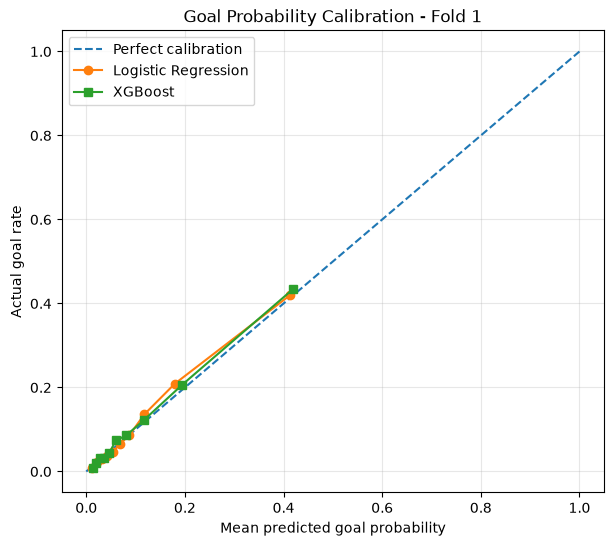

In [21]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

LogregActual, LogregPredicted = calibration_curve(
    YValid, FullValidProbabilities, n_bins=10, strategy="quantile"
)

XGBActual, XGBPredicted = calibration_curve(
    YValid, XGBValidProbabilities, n_bins=10, strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.plot(LogregPredicted, LogregActual, "o-", label="Logistic Regression")
plt.plot(XGBPredicted, XGBActual, "s-", label="XGBoost")

plt.xlabel("Mean predicted goal probability")
plt.ylabel("Actual goal rate")
plt.title("Goal Probability Calibration - Fold 1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

comparing pred vs actual goal 

In [22]:
ActualGoals = YValid.sum()

LogregExpectedGoals = FullValidProbabilities.sum()
XGBExpectedGoals = XGBValidProbabilities.sum()

print("Validation shots:", len(YValid))
print("Actual goals:", ActualGoals)
print("Logistic Regression expected goals:", round(LogregExpectedGoals, 2))
print("XGBoost expected goals:", round(XGBExpectedGoals, 2))

print("\nDifference from actual goals:")
print("Logistic Regression:", round(LogregExpectedGoals - ActualGoals, 2))
print("XGBoost:", round(XGBExpectedGoals - ActualGoals, 2))

Validation shots: 15047
Actual goals: 1594
Logistic Regression expected goals: 1545.15
XGBoost expected goals: 1526.88

Difference from actual goals:
Logistic Regression: -48.85
XGBoost: -67.12


final compar tbale

In [23]:
ModelComparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (Basic)",
        "Logistic Regression (Full)",
        "XGBoost (Full)"
    ],
    "Features": [2, 35, 35],
    "Validation AUC": [ValidAUC, FullValidAUC, XGBValidAUC],
    "CV Mean AUC": [np.nan, np.mean(LogregFoldAUC), np.mean(XGBFoldAUC)],
    "CV Std": [np.nan, np.std(LogregFoldAUC), np.std(XGBFoldAUC)]
})

print(ModelComparison.round(4).to_string(index=False))

                      Model  Features  Validation AUC  CV Mean AUC  CV Std
Logistic Regression (Basic)         2          0.7436          NaN     NaN
 Logistic Regression (Full)        35          0.8087       0.8009  0.0042
             XGBoost (Full)        35          0.8130       0.8106  0.0029


In [24]:
ValidationPredictions = ValidShots[
    ["id", "match_id", "goal"]
].copy()

ValidationPredictions["logreg_basic_xg"] = ValidProbabilities
ValidationPredictions["logreg_full_xg"] = FullValidProbabilities
ValidationPredictions["xgboost_xg"] = XGBValidProbabilities

print("Prediction rows:", len(ValidationPredictions))
print("Missing values:", ValidationPredictions.isna().sum().sum())
print(ValidationPredictions.head())

Prediction rows: 15047
Missing values: 0
                                       id  match_id  goal  logreg_basic_xg  \
908  ddd816bd-6e0b-4b35-a838-b4c11d319a25   3890563     0         0.032261   
909  3a9b7d9e-6294-4bd0-bc41-acb99b05272c   3890563     0         0.070332   
910  e7790d14-c223-45d2-b3c3-437c1e5c7ac8   3890563     0         0.150787   
911  1565e311-3882-46b7-9141-4b904309f6bc   3890563     1         0.205915   
912  7a049e7b-2158-4af5-9ac3-a81300a5b848   3890563     0         0.248414   

     logreg_full_xg  xgboost_xg  
908        0.017287    0.012121  
909        0.061740    0.070280  
910        0.115259    0.146011  
911        0.730379    0.897851  
912        0.356926    0.435033  


saving vald pred.

In [25]:
from pathlib import Path

OutputPath = Path("../data/features/goal_validation_predictions.parquet")

OutputPath.parent.mkdir(parents=True, exist_ok=True)

ValidationPredictions.to_parquet(OutputPath, index=False)

SavedPredictions = pd.read_parquet(OutputPath)

print("Saved to:", OutputPath)
print("Rows:", len(SavedPredictions))
print("Columns:", len(SavedPredictions.columns))
print("Matches original:", SavedPredictions.equals(ValidationPredictions))

Saved to: ..\data\features\goal_validation_predictions.parquet
Rows: 15047
Columns: 6
Matches original: False


checking if the data is saved

In [26]:
print("Original index:", ValidationPredictions.index[:5].tolist())
print("Saved index:", SavedPredictions.index[:5].tolist())

print(
    "Values match after resetting index:",
    SavedPredictions.equals(ValidationPredictions.reset_index(drop=True))
)

Original index: [908, 909, 910, 911, 912]
Saved index: [0, 1, 2, 3, 4]
Values match after resetting index: True
